In [1]:
!pip install numpy
!pip install pypiwin32
!pip install pandas
!pip install matplotlib
!pip install dss-python 

'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


'pip' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


In [2]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

In [5]:
os.chdir('C:\\Users\\brun\\Desktop\\aff\\bla\\')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path
print(mydir)                               # just to check if things worked out

C:\Users\brun\Desktop\aff\bla


In [6]:
dss_engine = dss.DSS
DSSText = dss_engine.Text                                                      
DSSCircuit = dss_engine.ActiveCircuit                                            
DSSSolution = dss_engine.ActiveCircuit.Solution                                      
ControlQueue = dss_engine.ActiveCircuit.CtrlQueue   

## Simulação 1: PV false, loadmult=1

Referência do alimentador, sem nada de PV e com a carga cheia. Tudo que vier depois se compara com essa.

Ordem: reset, cargas, solve, potência e perdas, potência das cargas, tensão, trafos, linhas, subestação.

In [7]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

In [8]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [9]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set stepsize=1h'
DSSText.Command = 'set number=1'  # each Solve call solves one hour only

nodesA = DSSCircuit.AllNodeNamesByPhase(1)  # nodes in phase 1
nodesB = DSSCircuit.AllNodeNamesByPhase(2)  # nodes in phase 2
nodesC = DSSCircuit.AllNodeNamesByPhase(3)  # nodes in phase 3

onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]

# Initialize variables to retrieve network data
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1 = [0 for i in range(24)]
busVpuB_SC1 = [0 for i in range(24)]
busVpuC_SC1 = [0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo), 24, 24))
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))
Line_Max_Amp = np.zeros((len(Linenames), 24))

# Solve power flow hour by hour
for h in range(24):

    DSSSolution.Solve()

    # Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0]
    Total_React_Power[h] = DSSCircuit.TotalPower[1]
    Total_Act_Losses[h] = DSSCircuit.Losses[0] / 1000
    Total_React_Losses[h] = DSSCircuit.Losses[1] / 1000

    # Voltage
    busVpuA_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(1)
    busVpuB_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(2)
    busVpuC_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(3)

    # Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
        DSSCircuit.Transformers.Name = trafo
        w = DSSCircuit.Transformers.WdgCurrents
        All_Wdg_Amp[itrafo, h, :len(w)] = w

    # Load power
    for iload, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        Load_kW[iload, h] = DSSCircuit.ActiveElement.TotalPowers[0]
        Load_kvar[iload, h] = DSSCircuit.ActiveElement.TotalPowers[1]

    # Maximum line current (first terminal only, any number of phases)
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' % line)
        elem = DSSCircuit.ActiveElement
        ncond = elem.NumConductors      # conductors per terminal
        mags = elem.CurrentsMagAng[0:2*ncond:2]
        Line_Max_Amp[iline, h] = max(mags)

In [10]:
i = onlytrafo.index('xfm1')
print(All_Wdg_Amp[i, :, :].round(3)[12])   # hora 12, todos os 24 valores crus

DSSCircuit.SetActiveElement('Transformer.xfm1')
print(DSSCircuit.ActiveElement.NormalAmps)
print(DSSCircuit.ActiveElement.Enabled)

[ 0. -0. -0.  0. -0.  0. -0. -0. -0.  0.  0.  0.  0.  0. -0.  0.  0.  0.
 -0. -0.  0. -0.  0. -0.]
66.15471834464462
True


In [11]:
Load_kW.sum( )

np.float64(35100.69312842795)

In [12]:
DSSCircuit.Transformers.Name = 'xfm1'
DSSCircuit.Transformers.WdgCurrents
 

array([ 5.33144885e-06, -2.04510698e-05, -1.43130394e-05,  1.58509399e-05,
       -5.89303181e-05,  2.92568893e-06, -3.08667622e-05, -4.89343302e-05,
       -2.04863923e-05,  6.06407446e-06,  2.07648309e-05,  4.01609384e-06,
        3.08667659e-05,  4.89343247e-05, -2.80635577e-05,  5.18600136e-05,
        1.51521199e-05,  1.43880968e-05, -6.45461495e-06, -1.98659325e-05,
        2.80635521e-05, -5.18600118e-05,  5.89303194e-05, -2.92568620e-06])

In [13]:
DSSCircuit.SetActiveElement('Transformer.xfm1')
print(DSSCircuit.ActiveElement.BusNames)

['709', '775']


In [14]:
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    print(load, DSSCircuit.ActiveElement.BusNames)

s701a ['701.1.2']
s701b ['701.2.3']
s701c ['701.3.1']
s712c ['712.3.1']
s713c ['713.3.1']
s714a ['714.1.2']
s714b ['714.2.3']
s718a ['718.1.2']
s720c ['720.3.1']
s722b ['722.2.3']
s722c ['722.3.1']
s724b ['724.2.3']
s725b ['725.2.3']
s727c ['727.3.1']
s728 ['728']
s729a ['729.1.2']
s730c ['730.3.1']
s731b ['731.2.3']
s732c ['732.3.1']
s733a ['733.1.2']
s734c ['734.3.1']
s735c ['735.3.1']
s736b ['736.2.3']
s737a ['737.1.2']
s738a ['738.1.2']
s740c ['740.3.1']
s741c ['741.3.1']
s742a ['742.1.2']
s742b ['742.2.3']
s744a ['744.1.2']


In [15]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

Total kWh delivered to the network: -36414.868 kWh
Total kVAr delivered to the network: -20385.579 kvarh
Total active losses: 1314.049 kWh
Percent losses: 3.609%
Total reactive losses 3197.780 kVArh


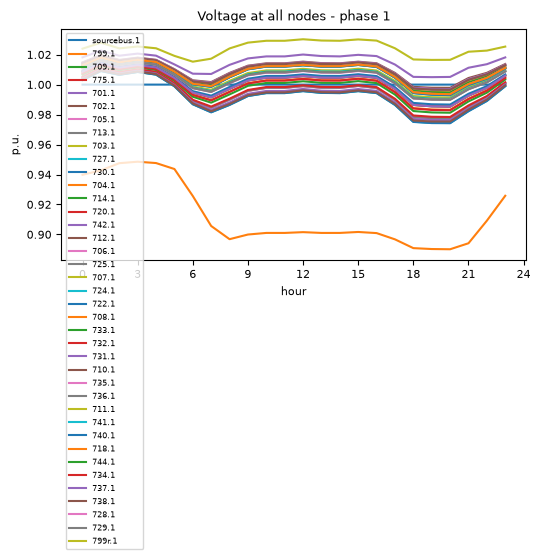

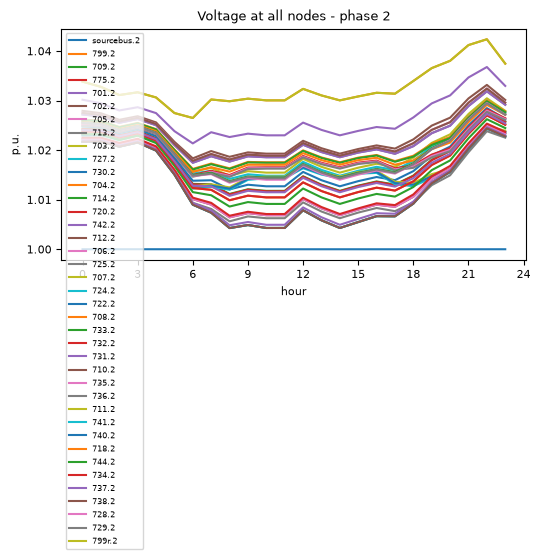

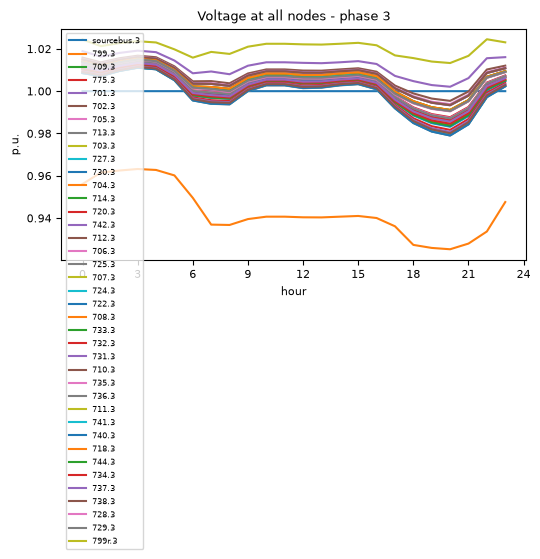

In [16]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop)

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop)

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop)

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
print("All_Wdg_Amp:", All_Wdg_Amp.shape)
print("Transf_Wdg1_Amps:", Transf_Wdg1_Amps.shape)

for i, trafo in enumerate(onlytrafo):
    print(trafo, len(DSSCircuit.Transformers.WdgCurrents))
print("onlytrafo:", onlytrafo)
print("onlytrafo:", onlytrafo)

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 2: PV false, loadmult=0.2

Mesma coisa da 1, só que com carga a 20%. No solve entra `set loadmult=0.2`.

Olhar: se alguma barra sobe de tensão mesmo sem PV.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA = DSSCircuit.AllNodeNamesByPhase(1)  # nodes in phase 1
nodesB = DSSCircuit.AllNodeNamesByPhase(2)  # nodes in phase 2
nodesC = DSSCircuit.AllNodeNamesByPhase(3)  # nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]

# Initialize variables to retrieve network data
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1 = [0 for i in range(24)]
busVpuB_SC1 = [0 for i in range(24)]
busVpuC_SC1 = [0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo), 24, 24))
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))
Line_Max_Amp = np.zeros((len(Linenames), 24))

# Solve power flow hour by hour
for h in range(24):

    DSSSolution.Solve()

    # Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0]
    Total_React_Power[h] = DSSCircuit.TotalPower[1]
    Total_Act_Losses[h] = DSSCircuit.Losses[0] / 1000
    Total_React_Losses[h] = DSSCircuit.Losses[1] / 1000

    # Voltage
    busVpuA_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(1)
    busVpuB_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(2)
    busVpuC_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(3)

    # Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
        DSSCircuit.Transformers.Name = trafo
        w = DSSCircuit.Transformers.WdgCurrents
        All_Wdg_Amp[itrafo, h, :len(w)] = w

    # Load power
    for iload, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        Load_kW[iload, h] = DSSCircuit.ActiveElement.TotalPowers[0]
        Load_kvar[iload, h] = DSSCircuit.ActiveElement.TotalPowers[1]

    # Maximum line current (first terminal only, any number of phases)
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' % line)
        elem = DSSCircuit.ActiveElement
        ncond = elem.NumConductors      # conductors per terminal
        mags = elem.CurrentsMagAng[0:2*ncond:2]
        Line_Max_Amp[iline, h] = max(mags)

In [ ]:
#All_Wdg_Amp = {t: [] for t in onlytrafo}
# dentro do loop
#All_Wdg_Amp[trafo].append(DSSCircuit.Transformers.WdgCurrents)


In [ ]:
All_Wdg_Amp

In [ ]:
for t in onlytrafo:
    DSSCircuit.Transformers.Name = t
    print(t, len(DSSCircuit.Transformers.WdgCurrents))

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
print(len(busVpuA_SC1))
print([np.shape(x) for x in busVpuA_SC1])

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop)

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop)

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop)

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
print(type(All_Wdg_Amp), np.shape(All_Wdg_Amp))
print(onlytrafo)

In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
print(type(All_Wdg_Amp), np.shape(All_Wdg_Amp))

In [ ]:
All_Wdg_Amp = np.zeros((len(onlytrafo), 24, 24))
print(type(All_Wdg_Amp), np.shape(All_Wdg_Amp))

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 3: PV true, loadmult=1

Igual à 1, mas roda o `pvpsys` antes do solve.

Olhar: sobretensão perto das barras com PV e se aparece fluxo reverso na subestação.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 4: PV true, loadmult=0.2

PV ligado com carga leve, ou seja, geração sobrando. No solve entra `set loadmult=0.2`.

Olhar: é o caso mais provável de sobretensão e fluxo reverso.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 5: PV true, loadmult=1, pmpp=x

Capacidade de hospedagem. Parte dos 307,125 kW por PV e vai aumentando o `pmpp` dos 8 juntos, mesmo valor pra todos, até a primeira restrição:

* sobretensão ou subtensão
* sobrecarga em linha ou transformador
* o fluxo de potência não convergir

Anotar o `pmpp` em que isso acontece e qual restrição foi.

A confirmar: o `kva` do inversor fica fixo ou cresce junto com o `pmpp`? Muda o resultado.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 6: PV true, loadmult=1, pmpp=x, storage central

Mesma base da 5, mais o `storagecentrall` depois do `pvpsys`.

* 1 unidade na barra 709
* `kWrated=2464` (soma das 8 unidades do distribuído) e `kWhrated=10000`
* `%stored=20`, `%reserve=20`, `effcurve=Eff`, `dispmode=follow`, `daily=dispatch_shape`

Objetivo: tirar o fluxo reverso e corrigir as tensões. Comparar com a 7.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 1 storage na barra 709
DSSText.Command = 'New Storage.StoCentral phases=3 bus1=709.1.2.3 kv=4.8 conn=delta kWrated=2464 kWhrated=10000 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

## Simulação 7: PV true, loadmult=1, pmpp=x, storage distribuído

Mesma base da 5, mais o `storagedist` depois do `pvpsys`.

* 8 unidades, uma em cada barra de PV: 728, 733, 737, 740, 718, 720, 722, 742
* `kWrated=308` e `kWhrated=1250` cada (10000 kWh no total)
* `%stored=20`, `%reserve=20`, `effcurve=Eff`, `dispmode=follow`, `daily=dispatch_shape`

Mesma energia total da 6, pra comparação ser justa. Comparar tensão, perdas, fluxo reverso e sobrecarga.

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 8 storages, um em cada barra de PV
DSSText.Command = 'New Storage.StoDist_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

# 
# **Ilhamento**
# 
# * Abrir a `L27` no terminal 1 (`Open Line.L27 Term=1`). Ela liga a 730 na 709.
# * Rodando a topologia no `.dss`, a ilha fica com as barras 708, 709, 710, 711, 731, 732, 733, 734, 735, 736, 737, 738, 740, 741 e 775.
# * PVs dentro da ilha: 733, 737, 740. Storage distribuído dessas mesmas. 
# *pvs com metade da capacidade, storage cheio, corte de carga
# **Storage**
# 
# * Começa 100% carregado (`%stored=100`) e desconectado da rede desde a hora 12.
# * Grid forming: `New InvControl.StoCtrl DERList=[...] mode=GFM` e o storage em `State=Discharging ControlMode=GFM`.
# * Rodar com o central e com o distribuído.
# 
# **Corte de carga**
# 
# * Industrial fica, residencial sai. Cortar em etapas, da menor prioridade pra maior, e ver quanto o tempo de sobrevivência aumenta em cada uma.
# * Comparar sobrevivência com corte e sem corte.
# 
# 
# # carga (kW) e prioridade de corte (menor prioridade primeiro)
# 
# [('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),('S733a',85),('S740c',85),('S738a',126),('S737a',140)]
# 
# 
# **Métrica:** tempo de sobrevivência.


In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 8 storages, um em cada barra de PV
DSSText.Command = 'New Storage.StoDist_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

In [ ]:
# ilhamento: abre a L27 no terminal 1 (liga a 730 na 709)
DSSText.Command = 'Open Line.L27 Term=1'

# carga (kW) e prioridade de corte, menor prioridade primeiro (ainda a confirmar)
CARGAS_ILHA = [('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),
               ('S733a',85),('S740c',85),('S738a',126),('S737a',140)]

N_CORTE = 0   # quantas cargas cortar, na ordem da lista (0 = sem corte). Muda e roda de novo a partir do Reset
for nome, kw in CARGAS_ILHA[:N_CORTE]:
    DSSText.Command = 'Edit Load.' + nome + ' enabled=no'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3

# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop,  )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

# ## Simulação 8: microrrede 
# 
# **Ilhamento**
# 
# * Abrir a `L27` no terminal 1 (`Open Line.L27 Term=1`). Ela liga a 730 na 709.
# * Rodando a topologia no `.dss`, a ilha fica com as barras 708, 709, 710, 711, 731, 732, 733, 734, 735, 736, 737, 738, 740, 741 e 775.
# * PVs dentro da ilha: 733, 737, 740. Storage distribuído nessas mesmas. Storage central na 709.
# # *ilhamento, pvs saem entao deve ser umas 1900,  storage nao sei ainda como vai estar , corte de carga

# **Storage**
# 
# * .
# * Grid forming: `New InvControl.StoCtrl DERList=[...] mode=GFM` e o storage em `State=Discharging ControlMode=GFM`.
# 
# **Corte de carga**
# 
# * Industrial fica, residencial sai. Cortar em etapas, da menor prioridade pra maior, e ver quanto o tempo de sobrevivência aumenta em cada uma.
# * Comparar sobrevivência com corte e sem corte.
# 
# 
# # carga (kW) e prioridade de corte (menor prioridade primeiro)
# 
# [('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),('S733a',85),('S740c',85),('S738a',126),('S737a',140)]
# 
# 
# **Métrica:** tempo de sobrevivência

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames


# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

In [ ]:
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
#def configure_power_flow({simulation_time}):
    DSSText.Command = 'reset'
    DSSText.Command = 'set controlmode=static'
    DSSText.Command = 'set mode=daily'
    DSSText.Command = 'set stepsize=1h'
    DSSText.Command = 'set number=1'  # each Solve call solves one hour only

    nodesA = DSSCircuit.AllNodeNamesByPhase(1)  # nodes in phase 1
    nodesB = DSSCircuit.AllNodeNamesByPhase(2)  # nodes in phase 2
    nodesC = DSSCircuit.AllNodeNamesByPhase(3)  # nodes in phase 3

    onlytrafo = DSSCircuit.Transformers.AllNames
    onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
    All_Wdg_Amp 
    Load_kW 
    Load_kvar 
    Line_Max_Amp 
    # Initialize variables to retrieve network data
    Total_Act_Power = [0 for i in range({simulation_time})]
    Total_React_Power = [0 for i in range({simulation_time})]
    Total_Act_Losses = [0 for i in range({simulation_time})]
    Total_React_Losses = [0 for i in range({simulation_time})]
    busVpuA_SC1 = [0 for i in range({simulation_time})]
    busVpuB_SC1 = [0 for i in range({simulation_time})]
    busVpuC_SC1 = [0 for i in range({simulation_time})]
    All_Wdg_Amp = np.zeros((len(onlytrafo), 24, 24))
    Load_kW = np.zeros((len(Loadnames), 24))
    Load_kvar = np.zeros((len(Loadnames), 24))
    Line_Max_Amp = np.zeros((len(Linenames), 24))

    # Solve power flow hour by hour
    for h in range({simulation_time}):

        DSSSolution.Solve()

        # Power injected and losses
        Total_Act_Power[h] = DSSCircuit.TotalPower[0]
        Total_React_Power[h] = DSSCircuit.TotalPower[1]
        Total_Act_Losses[h] = DSSCircuit.Losses[0] / 1000
        Total_React_Losses[h] = DSSCircuit.Losses[1] / 1000

        # Voltage
        busVpuA_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(1)
        busVpuB_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(2)
        busVpuC_SC1[h] = DSSCircuit.AllNodeVmagPUByPhase(3)

        # Transformer winding current
        for itrafo, trafo in enumerate(onlytrafo):
            DSSCircuit.Transformers.Name = trafo
            w = DSSCircuit.Transformers.WdgCurrents
            All_Wdg_Amp[itrafo, h, :len(w)] = w

        # Load power
        for iload, load in enumerate(Loadnames):
            DSSCircuit.SetActiveElement('load.%s' % load)
            Load_kW[iload, h] = DSSCircuit.ActiveElement.TotalPowers[0]
            Load_kvar[iload, h] = DSSCircuit.ActiveElement.TotalPowers[1]

        # Maximum line current (first terminal only, any number of phases)
        for iline, line in enumerate(Linenames):
            DSSCircuit.SetActiveElement('line.%s' % line)
            elem = DSSCircuit.ActiveElement
            ncond = elem.NumConductors      # conductors per terminal
            mags = elem.CurrentsMagAng[0:2*ncond:2]
            Line_Max_Amp[iline, h] = max(mags)

            

In [ ]:
# muda o x aqui e roda de novo a partir do Reset
pmpp_x = 307.125   # kW de cada PV (os 8 iguais), começa no valor da sim 3
kva_inv = 340      # por enquanto fixo, falta decidir se cresce junto com o pmpp

#Define curves fo the PV System: TempxPerature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]'


DSSText.Command = 'New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'


DSSText.Command = 'New loadshape.Irrad npts=24 interval=1  mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0] '


DSSText.Command = 'New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'
#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=' + str(pmpp_x) + ' kva=' + str(kva_inv) + ' temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp'

In [ ]:
# curva de eficiência e curva de despacho do storage (negativo carrega, positivo descarrega)
# a de despacho é rascunho meu, ajustar quando definir
DSSText.Command = 'New XYcurve.Eff npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]'
DSSText.Command = 'New LoadShape.dispatch_shape npts=24 interval=1 mult=[0 0 0 0 0 0 0 0 0 0 -0.3 -0.4 -0.45 -0.45 -0.45 -0.4 -0.15 0.2 0.4 0.6 0.6 0.4 0.2 0]'

# 8 storages, um em cada barra de PV
DSSText.Command = 'New Storage.StoDist_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'
DSSText.Command = 'New Storage.StoDist_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta kWrated=308 kWhrated=1250 %stored=20 %reserve=20 effcurve=Eff dispmode=follow daily=dispatch_shape pf=1'

In [ ]:
# ilhamento: abre a L27 no terminal 1 (liga a 730 na 709)
DSSText.Command = 'Open Line.L27 Term=1'

# carga (kW) e prioridade de corte, menor prioridade primeiro (ainda a confirmar)
CARGAS_ILHA = [('S736b',42),('S741c',42),('S732c',42),('S734c',42),('S735c',85),
               ('S733a',85),('S740c',85),('S738a',126),('S737a',140)]

N_CORTE = 0   # quantas cargas cortar, na ordem da lista (0 = sem corte). Muda e roda de novo a partir do Reset
for nome, kw in CARGAS_ILHA[:N_CORTE]:
    DSSText.Command = 'Edit Load.' + nome + ' enabled=no'

In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3
onlytrafo = DSSCircuit.Transformers.AllNames
onlytrafo = [name for name in onlytrafo if 'reg' not in name.lower()]
# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#-------Results for Energy
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents
# 
# # Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kWh" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvarh" %kVArh_SC1)
print("Total active losses: %.3f kWh" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVArh" %kVArh_Loss_SC1)

In [ ]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.vstack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.vstack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.vstack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop,  )

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop, )

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


In [ ]:
#-----Results for Amps Loading at each phase in pu for each transformer

#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])

Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.vstack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.vstack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)


#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.vstack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()